In [ ]:
import pandas as pd

data = pd.read_parquet("../data/pitches_2024.parquet")

In [24]:
data['count'] = data['balls'].astype(str) + "-" + data['strikes'].astype(str)
data["batter_idx"], unique_batters = pd.factorize(data["batter"])
data["pitcher_idx"], unique_pitcher = pd.factorize(data["pitcher"])
data["outcome_idx"], unique_outcome = pd.factorize(data["description"])
data['count_idx'], unique_counts = pd.factorize(data["count"])

In [26]:
from tensorflow.keras import optimizers
from tensorflow.keras.layers import Activation, concatenate, Dense, Dropout, Embedding, Input, Reshape
from tensorflow.keras.models import Model

NUM_BATTERS = len(unique_batters)
NUM_PITCHERS = len(unique_pitcher)
NUM_COUNT = len(unique_counts)
VEC_SIZE = 9
ACTIVATION = "sigmoid"
NUM_OUTCOMES = len(unique_outcome)

batter_idx = Input(shape = (1, ), dtype = "int32", name = "batter_idx")
batter_embed = Embedding(NUM_BATTERS, VEC_SIZE)(batter_idx)
batter_embed = Reshape((VEC_SIZE, ), name = "batter_embed")(batter_embed)
batter_embed = Activation(ACTIVATION)(batter_embed)

pitcher_idx = Input(shape = (1, ), dtype = "int32", name = "pitcher_idx")
pitcher_embed = Embedding(NUM_PITCHERS, VEC_SIZE)(pitcher_idx)
pitcher_embed = Reshape((VEC_SIZE, ), name = "pitcher_embed")(pitcher_embed)
pitcher_embed = Activation(ACTIVATION)(pitcher_embed)

count_idx = Input(shape = (1, ), dtype = "int32", name = "count_idx")
count_embed = Embedding(NUM_COUNT, VEC_SIZE)(count_idx)
count_embed = Reshape((VEC_SIZE, ), name = "count_embed")(count_embed)
count_embed = Activation(ACTIVATION)(count_embed)

batter_pitcher = concatenate([batter_embed, pitcher_embed, count_embed], name = "batter_pitcher")

output = Dense(NUM_OUTCOMES, activation = "softmax")(batter_pitcher)

model = Model(inputs = [batter_idx, pitcher_idx, count_idx], outputs = [output])

learning_rate = optimizers.schedules.InverseTimeDecay(
    initial_learning_rate = 0.01, decay_steps = 1, decay_rate = 1e-6)
sgd = optimizers.SGD(learning_rate = learning_rate, momentum = 0.9, nesterov = True)
model.compile(optimizer = sgd, loss = "categorical_crossentropy")

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
indices = np.array(data["outcome_idx"])
num_classes = len(unique_outcome) 

matrix = np.zeros((len(indices), num_classes), dtype=int)
matrix[np.arange(len(indices)), indices] = 1

X_list = [np.array(data["batter_idx"]), np.array(data["pitcher_idx"]), np.array(data['count_idx'])]
y = matrix

BATCH_SIZE = 100
NUM_EPOCHS = 100
VALID = False
callbacks = None

validation_split = 0.01


history = model.fit(X_list, y, epochs = NUM_EPOCHS, batch_size = BATCH_SIZE,
                    verbose = 2, shuffle = True, callbacks = callbacks, validation_split = validation_split)


Epoch 1/100
7527/7527 - 24s - 3ms/step - loss: 1.6863 - val_loss: 1.7774
Epoch 2/100
7527/7527 - 23s - 3ms/step - loss: 1.6642 - val_loss: 1.7708
Epoch 3/100
7527/7527 - 14s - 2ms/step - loss: 1.6615 - val_loss: 1.7860
Epoch 4/100
7527/7527 - 18s - 2ms/step - loss: 1.6594 - val_loss: 1.7615
Epoch 5/100
7527/7527 - 23s - 3ms/step - loss: 1.6572 - val_loss: 1.7637
Epoch 6/100
7527/7527 - 24s - 3ms/step - loss: 1.6547 - val_loss: 1.7743
Epoch 7/100
7527/7527 - 17s - 2ms/step - loss: 1.6521 - val_loss: 1.7759
Epoch 8/100


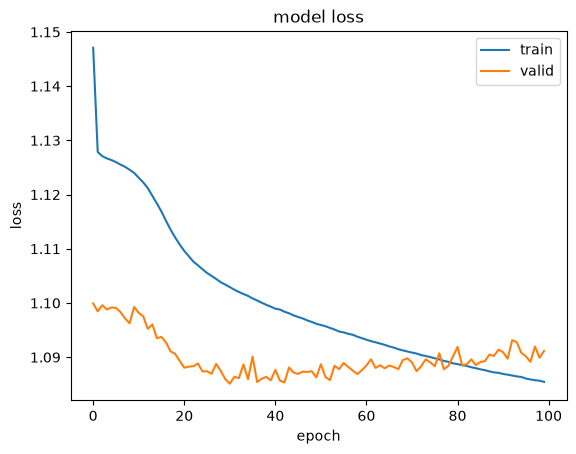

In [19]:
#ab data
plt.plot(history.history["loss"])
plt.plot(history.history["val_loss"])
plt.title("model loss")
plt.ylabel("loss")
plt.xlabel("epoch")
plt.legend(["train", "valid"], loc = "upper right")
plt.show()